# Hybrid 03 · All-year hybrid evaluation, missing information and the 2023 pattern

**Objective:** evaluate tabular, hybrid and image-only models on all image-matched tissues with donor-grouped CV, test whether images help when information is missing, and show the evidence that led to excluding 2023 tissues from the primary cohort.

**Derived from:** `notebooks/images/07_hybrid_evaluation.ipynb` (planned), `notebooks/images/08_missing_information.ipynb` (C1–C5 planned; Section 10 diagnostic), `ANALYSIS_PLAN.md` Amendment 1.
**Cohort / design:** K2 (1,009 tissues, all years), V2 (5 × 5 donor-grouped folds). Random Forest settings from notebook 05, identical in every arm. **Runtime:** about 4 minutes.

> These are **all-year** results. They are not comparable with the primary-cohort results in Hybrid 04–09 (different tissues).

Set up paths, the image cohort K2 and its feature matrix.

In [1]:
import sys
import time
import warnings
from pathlib import Path

GRADING_DIR = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "scripts" / "modeling_setup.py").is_file())
sys.path[:0] = [str(GRADING_DIR / "scripts"), str(GRADING_DIR / "notebooks_cleaned")]

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import balanced_accuracy_score, f1_score, recall_score, roc_auc_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

import cleaned_setup as cs
import modeling_setup as ms

warnings.filterwarnings("ignore", category=UserWarning)
k2, folds = cs.image_cohort()
X, y, donors = cs.feature_matrix(k2)
SLIT_LAMP, KONAN = ms.CLINICAL_FEATURES, ms.NUMERIC_FEATURES
print("K2:", len(k2), "tissues,", k2["Donor_Group"].nunique(), "donors | feature matrix", X.shape)

K2: 1009 tissues, 770 donors | feature matrix (1009, 2072)


## 1. Missing information is tied to the year

Classify each tissue's slit-lamp and Konan availability (all features missing = "Missing") and its year (Konan exam year, falling back to the `Tissue_ID` year, as in notebook 08).

In [2]:
def availability(columns):
    present = k2[columns].notna().sum(axis=1)
    return np.select([present == 0, present == len(columns)], ["Missing", "Complete"], default="Partial")


k2["Slit_lamp"], k2["Konan"] = availability(SLIT_LAMP), availability(KONAN)
year = pd.to_datetime(k2["Konan_Exam_Date"], errors="coerce").dt.year
k2["Year"] = year.fillna(k2["Tissue_ID"].str.extract(r"NEB-\s*(\d{4})")[0].astype(float)).astype("Int64")
by_year = pd.DataFrame({
    "Tissues": k2.groupby("Year").size(),
    "Slit-lamp missing %": k2.groupby("Year")["Slit_lamp"].apply(lambda s: (s == "Missing").mean() * 100),
    "Konan missing %": k2.groupby("Year")["Konan"].apply(lambda s: (s == "Missing").mean() * 100),
}).round(1)
by_year

,Tissues,Slit-lamp missing %,Konan missing %
Year,,,
2020,128,0.0,39.1
2021,12,0.0,8.3
2022,58,0.0,6.9
2023,455,100.0,0.9
2024,171,1.8,7.6
2025,185,0.0,7.0


How often the recorded grade equals the eye bank's ECD rule (below 2250 → B, 2250 to below 2500 → A, 2500 and above → A+), by year. Reported descriptively: notebook 08 could not cite a written copy of the criteria.

In [3]:
ecd = k2[cs.ECD]
rule = np.full(len(k2), None, dtype=object)
rule[ecd.notna().to_numpy()] = cs.ecd_rule(ecd.dropna().to_numpy())
agreement = (pd.DataFrame({"Year": k2["Year"], "Agrees": rule == y})[ecd.notna().to_numpy()]
             .groupby("Year")["Agrees"].agg(["size", "mean"]).rename(columns={"size": "Tissues", "mean": "Agreement"}))
agreement.round(3)

,Tissues,Agreement
Year,,
2020,78,0.756
2021,11,0.818
2022,54,0.722
2023,451,0.951
2024,158,0.823
2025,172,0.837


Both patterns side by side: in 2023 every slit-lamp record is missing **and** recorded grades follow the ECD thresholds almost exactly.

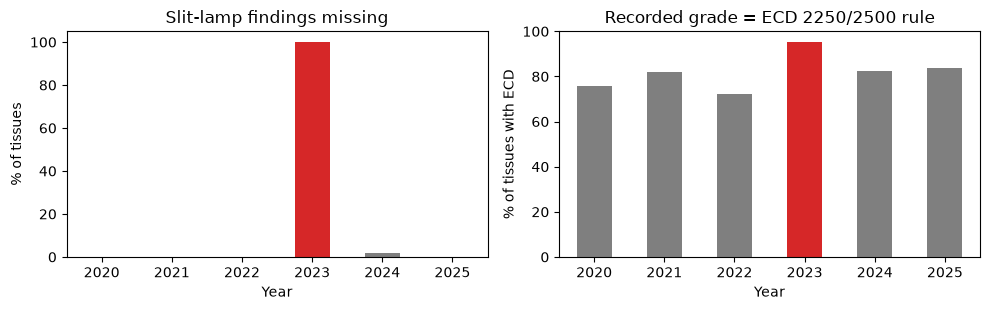

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.2))
by_year["Slit-lamp missing %"].plot.bar(ax=axes[0], color=["tab:red" if y_ == 2023 else "tab:grey" for y_ in by_year.index])
axes[0].set(title="Slit-lamp findings missing", ylabel="% of tissues", xlabel="Year")
agreement["Agreement"].mul(100).plot.bar(ax=axes[1], color=["tab:red" if y_ == 2023 else "tab:grey" for y_ in agreement.index])
axes[1].set(title="Recorded grade = ECD 2250/2500 rule", ylabel="% of tissues with ECD", xlabel="Year", ylim=(0, 100))
for ax in axes:
    ax.tick_params(axis="x", rotation=0)
plt.tight_layout()
plt.show()

## 2. Model arms

Arms from notebook 07 (tabular, hybrid with PCA 16, image only, PCA 8/32 sensitivity) and notebook 08 (pre-examination arms trained without slit-lamp findings). All use the notebook 05 Random Forest; all preprocessing is inside the pipeline.

In [5]:
def konan_arm(with_image):
    branches = [("tabular", ms.make_preprocessor(KONAN, [], []), KONAN)]
    if with_image:
        branches.append(("image", Pipeline([("scaler", StandardScaler()),
                                            ("pca", PCA(n_components=16, random_state=cs.SEED))]), cs.EMBEDDING_COLUMNS))
    return Pipeline([("features", ColumnTransformer(branches, remainder="drop")),
                     ("classifier", RandomForestClassifier(**cs.NB05_RF_PARAMS))])


ARMS = {
    "Tabular": cs.rf_pipeline(),
    "Hybrid (PCA 16)": cs.rf_pipeline(n_components=16),
    "Image only (PCA 16)": cs.rf_pipeline(n_components=16, tabular=False),
    "Hybrid (PCA 8)": cs.rf_pipeline(n_components=8),
    "Hybrid (PCA 32)": cs.rf_pipeline(n_components=32),
    "Konan only": konan_arm(with_image=False),
    "Konan + image": konan_arm(with_image=True),
}


def mask(X_part, columns):
    masked = X_part.copy()
    masked[columns] = np.nan  # passes through the same imputation as naturally missing values
    return masked

## 3. Donor-grouped cross-validation (25 folds)

Fit every arm on each training fold and predict the held-out donors, unmasked and with slit-lamp or Konan values removed at test time (≈3–4 min).

In [6]:
records, fold_sizes = [], []
start = time.time()
for repeat in range(ms.N_REPEATS):
    for fold, (train, test) in enumerate(ms.iter_donor_folds(folds, k2["Tissue_ID"], repeat)):
        assert set(donors[train]).isdisjoint(donors[test]), "Donor leak"
        fold_sizes.append((len(train), len(test)))
        fitted = {name: clone(arm).fit(X.iloc[train], y[train]) for name, arm in ARMS.items()}
        X_test = X.iloc[test]
        predictions = {("Unmasked", name): model.predict(X_test) for name, model in fitted.items()
                       if name not in ("Konan only", "Konan + image")}
        predictions.update({
            ("Slit-lamp masked", "Tabular"): fitted["Tabular"].predict(mask(X_test, SLIT_LAMP)),
            ("Slit-lamp masked", "Hybrid"): fitted["Hybrid (PCA 16)"].predict(mask(X_test, SLIT_LAMP)),
            ("Konan masked", "Tabular"): fitted["Tabular"].predict(mask(X_test, KONAN)),
            ("Konan masked", "Hybrid"): fitted["Hybrid (PCA 16)"].predict(mask(X_test, KONAN)),
            ("Pre-examination", "Tabular"): fitted["Konan only"].predict(X_test),
            ("Pre-examination", "Hybrid"): fitted["Konan + image"].predict(X_test),
        })
        for (condition, arm), pred in predictions.items():
            records.append(pd.DataFrame({"Repeat": repeat, "Fold": fold, "Row": test,
                                         "Condition": condition, "Arm": arm, "Pred": pred}))
predictions = pd.concat(records, ignore_index=True)
N_TRAIN, N_TEST = np.mean(fold_sizes, axis=0)
print(f"{len(fold_sizes)} folds × {len(ARMS)} arms in {(time.time() - start) / 60:.1f} min")

25 folds × 7 arms in 2.5 min


Reproducibility check: the unmasked predictions must equal the out-of-fold predictions saved by notebook 07.

In [7]:
saved = pd.read_csv(ms.PROCESSED_DIR / "hybrid_oof_predictions.csv")
unmasked = predictions[predictions["Condition"] == "Unmasked"].assign(Tissue_ID=lambda d: k2["Tissue_ID"].to_numpy()[d["Row"]])
for arm in ["Tabular", "Hybrid (PCA 16)", "Image only (PCA 16)", "Hybrid (PCA 8)", "Hybrid (PCA 32)"]:
    ours = unmasked[unmasked["Arm"] == arm].merge(saved[["Tissue_ID", "Repeat", arm]], on=["Tissue_ID", "Repeat"])
    match = (ours["Pred"] == ours[arm]).mean()
    print(f"{arm}: {match:.1%} of {len(ours)} predictions match notebook 07")
    assert match == 1.0

Tabular: 100.0% of 5045 predictions match notebook 07
Hybrid (PCA 16): 100.0% of 5045 predictions match notebook 07
Image only (PCA 16): 100.0% of 5045 predictions match notebook 07
Hybrid (PCA 8): 100.0% of 5045 predictions match notebook 07
Hybrid (PCA 32): 100.0% of 5045 predictions match notebook 07


## 4. All-year results (notebook 07)

Fold-level metrics per arm, mean ± SD over 25 folds.

In [8]:
fold_scores = pd.DataFrame([
    {"Arm": arm, "Repeat": r, "Fold": f, **{m: fn(y[g["Row"]], g["Pred"]) for m, fn in cs.METRICS.items()}}
    for (r, f, arm), g in unmasked.groupby(["Repeat", "Fold", "Arm"])
])
NB07_ARMS = ["Tabular", "Hybrid (PCA 16)", "Image only (PCA 16)", "Hybrid (PCA 8)", "Hybrid (PCA 32)"]
cs.summarise(fold_scores, NB07_ARMS, ["Macro F1", "Balanced accuracy", "Accuracy"], by="Arm")

,Macro F1,Balanced accuracy,Accuracy
Tabular,0.849 ± 0.021,0.841 ± 0.023,0.850 ± 0.020
Hybrid (PCA 16),0.859 ± 0.025,0.841 ± 0.028,0.861 ± 0.024
Image only (PCA 16),0.442 ± 0.033,0.442 ± 0.033,0.504 ± 0.033
Hybrid (PCA 8),0.845 ± 0.026,0.829 ± 0.029,0.846 ± 0.024
Hybrid (PCA 32),0.852 ± 0.023,0.833 ± 0.025,0.855 ± 0.023


Paired hybrid − tabular differences on identical held-out donors (corrected repeated-CV t-test). PCA 8 and 32 are pre-set sensitivity arms.

In [9]:
comparisons = {f"PCA {k}": (f"Hybrid (PCA {k})", "Tabular") for k in [16, 8, 32]}
paired = cs.paired_comparisons(fold_scores, comparisons, ["Macro F1", "Balanced accuracy", "Accuracy"], N_TRAIN, N_TEST, by="Arm")
paired[["ID", "Metric", "Difference", "CI low", "CI high", "p", "Folds improved"]].round(4)

,ID,Metric,Difference,CI low,CI high,p,Folds improved
0,PCA 16,Macro F1,0.0098,-0.0118,0.0313,0.3589,16/25
1,PCA 16,Balanced accuracy,-0.0004,-0.0215,0.0207,0.9710,11/25
2,PCA 16,Accuracy,0.0115,-0.0131,0.0361,0.3454,15/25
3,PCA 8,Macro F1,-0.0044,-0.0260,0.0172,0.6776,11/25
4,PCA 8,Balanced accuracy,-0.0121,-0.0334,0.0093,0.2547,5/25
5,PCA 8,Accuracy,-0.0032,-0.0250,0.0187,0.7664,11/25
6,PCA 32,Macro F1,0.0032,-0.0209,0.0274,0.7837,16/25
7,PCA 32,Balanced accuracy,-0.0082,-0.0299,0.0135,0.4410,10/25
8,PCA 32,Accuracy,0.0053,-0.0198,0.0305,0.6668,14/25


Per-grade recall pooled over repeats: images shift errors rather than remove them (grade B recall falls).

In [10]:
y_pooled = np.tile(y, ms.N_REPEATS)
pooled = {arm: unmasked[unmasked["Arm"] == arm].sort_values(["Repeat", "Row"])["Pred"].to_numpy()
          for arm in ["Tabular", "Hybrid (PCA 16)", "Image only (PCA 16)"]}
cs.per_grade(y_pooled, pooled).round(3)

Tabular        Hybrid (PCA 16)        Image only (PCA 16)       
   Precision Recall       Precision Recall           Precision Recall
A+     0.878  0.886           0.866  0.920               0.629  0.655
A      0.763  0.787           0.797  0.783               0.365  0.345
B      0.935  0.851           0.987  0.819               0.335  0.325

## 5. Do images help when information is missing? (notebook 08, C1–C5)

Each comparison is hybrid − tabular on the same tissues. Natural subgroups (C1, C2) use unmasked predictions; C3/C4 remove one source at test time; C5 trains and tests without slit-lamp findings. Metrics follow notebook 08 (macro F1 over the grades present in a subgroup fold; grade B recall is undefined in folds without a B tissue).

In [11]:
def macro_f1_nb08(true, pred):
    return f1_score(true, pred, average="macro", zero_division=0)


def recall_b_nb08(true, pred):
    return np.nan if not (true == "B").any() else recall_score(true, pred, labels=["B"], average="macro", zero_division=0)


NB08_METRICS = {"Macro F1": macro_f1_nb08, "Balanced accuracy": balanced_accuracy_score, "Recall B": recall_b_nb08}


# Notebook 08 names the unmasked primary hybrid (PCA 16) simply "Hybrid".
nb08 = predictions.replace({"Arm": {"Hybrid (PCA 16)": "Hybrid"}})
nb08 = nb08[nb08["Arm"].isin(["Tabular", "Hybrid"])]


def fold_metrics(condition, rows_mask):
    subset = nb08[(nb08["Condition"] == condition) & nb08["Row"].isin(np.flatnonzero(rows_mask))]
    return pd.DataFrame([
        {"Repeat": r, "Fold": f, "Arm": arm, "N": len(g), **{m: fn(y[g["Row"].to_numpy()], g["Pred"].to_numpy()) for m, fn in NB08_METRICS.items()}}
        for (r, f, arm), g in subset.groupby(["Repeat", "Fold", "Arm"])
    ])


def compare(label, condition, rows_mask):
    wide = fold_metrics(condition, rows_mask).pivot_table(index=["Repeat", "Fold"], columns="Arm", values=list(NB08_METRICS))
    rows = []
    for metric in NB08_METRICS:
        d = wide[(metric, "Hybrid")] - wide[(metric, "Tabular")]
        mean, low, high, _, p = cs.corrected_ttest(d, N_TRAIN, N_TEST)
        rows.append({"Comparison": label, "Metric": metric, "Tabular": wide[(metric, "Tabular")].mean(),
                     "Hybrid": wide[(metric, "Hybrid")].mean(), "Difference": mean, "CI low": low, "CI high": high,
                     "p": p, "Folds": int(d.notna().sum())})
    return pd.DataFrame(rows)


slit_missing = (k2["Slit_lamp"] == "Missing").to_numpy()
konan_missing = (k2["Konan"] == "Missing").to_numpy()
everyone = np.ones(len(k2), dtype=bool)
results = pd.concat([
    compare("C1: slit-lamp missing", "Unmasked", slit_missing),
    compare("Ref: slit-lamp available", "Unmasked", ~slit_missing),
    compare("C2: Konan missing", "Unmasked", konan_missing),
    compare("Ref: Konan available", "Unmasked", ~konan_missing),
    compare("C3: slit-lamp masked at test", "Slit-lamp masked", ~slit_missing),
    compare("C4: Konan masked at test", "Konan masked", ~konan_missing),
    compare("C5: pre-examination (no slit-lamp)", "Pre-examination", everyone),
], ignore_index=True)

Reproducibility check against `missing_information_results.csv` (notebook 08).

In [12]:
saved08 = pd.read_csv(ms.PROCESSED_DIR / "missing_information_results.csv")
merged = results.merge(saved08, on=["Comparison", "Metric"], suffixes=("", " saved"))
diff = max((merged[c] - merged[f"{c} saved"]).abs().max() for c in ["Tabular", "Hybrid", "Difference", "CI low", "CI high", "p"])
print(f"{len(merged)} rows compared; max absolute difference from notebook 08 = {diff:.1e}")
assert len(merged) == len(saved08) and diff < 1e-9

21 rows compared; max absolute difference from notebook 08 = 1.1e-16


Primary comparisons (macro F1), Holm-corrected across C1–C5.

In [13]:
primary = results[results["Comparison"].str.startswith("C") & (results["Metric"] == "Macro F1")].copy()
primary["p (Holm)"] = cs.holm(primary["p"])
grade_b = results[results["Comparison"].str.startswith("C") & (results["Metric"] == "Recall B")].set_index("Comparison")["Difference"]
primary["Grade B recall difference"] = primary["Comparison"].map(grade_b)
primary.drop(columns=["Metric", "Folds"]).round(4)

,Comparison,Tabular,Hybrid,Difference,CI low,CI high,p,p (Holm),Grade B recall difference
0,C1: slit-lamp missing,0.9921,0.9702,-0.0219,-0.0445,0.0006,0.0564,0.1692,-0.0411
6,C2: Konan missing,0.4702,0.4025,-0.0677,-0.2350,0.0997,0.4121,0.8241,-0.3160
12,C3: slit-lamp masked at test,0.6782,0.7398,0.0616,0.0239,0.0993,0.0025,0.0127,-0.1395
15,C4: Konan masked at test,0.3057,0.3668,0.0610,0.0113,0.1108,0.0183,0.0732,-0.6296
18,C5: pre-examination (no slit-lamp),0.8450,0.8502,0.0053,-0.0232,0.0337,0.7062,0.8241,0.0146


## 6. Diagnostics: the 2023 subset (added after the results, notebook 08 Section 10)

Performance of the unmasked models within each era: the pooled ~0.85 averages a near-perfect 2023 subset with much lower other years.

In [14]:
era_2023 = (k2["Year"] == 2023).to_numpy()
pd.concat([
    compare("2023", "Unmasked", era_2023),
    compare("Other years", "Unmasked", ~era_2023),
]).query("Metric == 'Macro F1'").set_index("Comparison")[["Tabular", "Hybrid", "Difference", "CI low", "CI high", "p"]].round(4)

,Tabular,Hybrid,Difference,CI low,CI high,p
Comparison,,,,,,
2023,0.9920,0.9705,-0.0215,-0.0437,0.0006,0.0556
Other years,0.7294,0.7649,0.0355,-0.0042,0.0751,0.0776


Why C3 is a masking artefact: masking slit-lamp findings on other-year tissues pushes the tabular model toward the 2023-style ECD rule.

In [15]:
other_with_ecd = np.flatnonzero(~era_2023 & ~slit_missing & ecd.notna().to_numpy())
pd.DataFrame([
    {"Condition": condition, "Arm": arm,
     "Agreement with ECD rule": (sub["Pred"].to_numpy() == rule[sub["Row"]]).mean(),
     "Agreement with recorded grade": (sub["Pred"].to_numpy() == y[sub["Row"]]).mean()}
    for condition in ["Unmasked", "Slit-lamp masked"] for arm in ["Tabular", "Hybrid"]
    for sub in [nb08[(nb08["Condition"] == condition) & (nb08["Arm"] == arm) & nb08["Row"].isin(other_with_ecd)]]
]).round(3)

,Condition,Arm,Agreement with ECD rule,Agreement with recorded grade
0,Unmasked,Tabular,0.850,0.769
1,Unmasked,Hybrid,0.870,0.808
2,Slit-lamp masked,Tabular,0.946,0.818
3,Slit-lamp masked,Hybrid,0.947,0.813


Can the image embeddings identify 2023 tissues? (If strongly, the hybrid could recognise the era rather than read clinical information.)

In [16]:
era_auc = []
for repeat in range(ms.N_REPEATS):
    for train, test in ms.iter_donor_folds(folds, k2["Tissue_ID"], repeat):
        model = Pipeline([("scaler", StandardScaler()), ("pca", PCA(n_components=16, random_state=cs.SEED)),
                          ("classifier", RandomForestClassifier(**cs.NB05_RF_PARAMS))])
        embeddings = X[cs.EMBEDDING_COLUMNS].to_numpy()
        model.fit(embeddings[train], era_2023[train])
        era_auc.append(roc_auc_score(era_2023[test], model.predict_proba(embeddings[test])[:, 1]))
print(f"Image embeddings predicting 2023 vs other years: AUC {np.mean(era_auc):.3f} ± {np.std(era_auc):.3f}")

Image embeddings predicting 2023 vs other years: AUC 0.621 ± 0.042


## Interpretation

- **All years (planned, notebook 07):** adding frozen embeddings changed macro F1 by +0.010 [−0.012, +0.031], p = 0.36, not robust to PCA size; grade B recall fell (0.851 → 0.819). Image-only reached 0.44, so the embeddings carry some grade information, much of it plausibly overlapping the Konan measurements.
- **Missing information (C1–C5):** C1 is the 2023 subset where tabular is at ceiling; C3 is significant only because masking mimics the 2023 pattern, with grade B recall falling; C5, the cleanest test, shows no gain. Images did not reliably compensate for missing information.
- **Why 2023 was excluded:** every 2023 tissue lacks slit-lamp findings (unrecoverable), so a multimodal analysis of findings, morphology and images is impossible there. Recorded 2023 grades also follow the ECD thresholds in ~95% of tissues against 72–84% in other years, and pooled metrics hide this. The primary cohort became non-2023 tissues (Amendment 1).

**Limitations:** the exclusion decision was made **after** these results were known (timing disclosed in `ANALYSIS_PLAN.md`). The patterns describe the recorded data; they do not show why 2023 grades follow ECD so closely. The Random Forest settings came from notebook 05 (later shown to under-tune the tabular arm, Hybrid 06). Year here is the exam year (notebook 08); Hybrid 04 onward uses the `Tissue_ID` year, which moves 3 tissues.